# Experiment 7 — Predictive tactical deconfliction with a dynamic geofence

A cylindrical KEEP-OUT geofence is dynamically activated ahead of a UAV, while the vehicle is still outside the restricted region. Strategic deconfliction is disabled. The experiment verifies whether the predicted track allows tactical deconfliction to modify the route before any geofence violation occurs.

In [1]:
from pathlib import Path

from IPython.display import Image, Markdown, display

from musas.airspace import Airspace, Cylinder3D, Geofence
from musas.algorithms import (
    FirstOrderDynamics,
    FlightPlanAwareTracking,
    HybridGeometricManeuver,
    MinimumSeparationTacticalConflictPrediction,
    WaypointGuidance,
)
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    plot_dataset,
)
from musas.simulation.metrics import calculate_metrics

OUTPUT_DIRECTORY = Path("outputs") / "output_7"
FIGURE_DIRECTORY = Path("figs") / "figs_7"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)

## Parameters

| Component | Parameter | Value | Note |
|---|---|---:|---|
| Experiment | Cases | Without TD; With TD | Used |
| Experiment | Simulation end | 45.0 s | Used |
| Flight plan | Start / destination | $(-120,0,100)$ / $(120,0,100)$ m | Used |
| Flight plan | Start / arrival time | 2.0 / 26.0 s | Used |
| Flight plan | Priority | 0 | Default |
| Dynamic geofence | Geometry | Cylinder3D | Used |
| Dynamic geofence | Center / radius | $(20,0)$ / 20.0 m | Used |
| Dynamic geofence | Vertical limits | 0.0–200.0 m | Used |
| Dynamic geofence | Activation time | 10.0 s | UAV is outside and approaching the region |
| Dynamic geofence | Removal time | None | Remains active |
| Tracking | Algorithm | FlightPlanAwareTracking | Used in both cases |
| Tracking | Report interval | 0.25 s | Used |
| Tracking | History window | 6 reports | Default |
| Tracking | Prediction horizon | 24 steps | Used |
| Tracking | Prediction step | 0.25 s | Used; total horizon = 6.0 s |
| Tactical CP | Algorithm | MinimumSeparationTacticalConflictPrediction | With-TD case only |
| Tactical CP | Minimum separation | 30.0 m | Default; relevant to U2U |
| Tactical CP | Maximum time difference | 0.25 s | Used |
| Tactical deconfliction | Algorithm | HybridGeometricManeuver | With-TD case only |
| Tactical deconfliction | Vertical offset | 40.0 m | Default; airspace maneuver is lateral |
| Tactical deconfliction | Airspace clearance | 15.0 m | Used |
| Tactical deconfliction | Maneuver / recovery duration | 4.0 / 8.0 s | Used / default |
| Tactical deconfliction | Minimum / maximum speed | 1.0 / 15.0 m/s | Default / used |
| Tactical deconfliction | Cooldown | 2.0 s | Used |
| Tactical deconfliction | Maximum escape distance | 500.0 m | Default |
| Simulation | Strategic deconfliction | Disabled | Prevents information leakage before activation |
| Simulation | Tactical-assessment interval | 0.25 s | Used |
| Simulation | Network delay | 0.0 s | Default |
| Simulation | Flight-update interval | 0.1 s | Default |
| Simulation | Trajectory-record interval | 0.2 s | Default |
| Simulation | Collision distance | 1.0 m | Default; U2U only |
| Simulation | Processing times | 0.0 s | Defaults |
| UAV | Submission time | 0.0 s | Default |
| UAV | Waypoint acceptance radius | 1.0 m | Default |
| Dynamics | Velocity time constant / max. acceleration | 0.0 s / 100.0 m/s² | Used |
| Guidance | Minimum / maximum speed | 0.0 / 15.0 m/s | Default / used |
| Sensor | Sensor model | PerfectSensor | UAV default |
| Dataset | Flush interval / keep history | 10.0 s / True | Defaults |
| Dataset | Overwrite existing file | True | Used |
| Network events | Message types logged | None | Used |
| Metrics | Minimum separation / collision distance | 30.0 / 1.0 m | Used |
| Visualization | Before / activation / response snapshots | 9.75 / 10.0 / 12.0 s | Used |
| Visualization | View | XY | Used |
| Visualization | Frame step | 0.25 s | Used |
| Visualization | Figure size / static DPI | $(8.0,5.5)$ in / 300 | Defaults |
| Visualization | Animation FPS / DPI | 10 / 120 | Used / default |
| Visualization | Plan, trajectory, tracks, geofence, legend, grid | Shown | Used/default |
| Visualization | Reports, wind zones and obstacles | Hidden | Used |

In [2]:
SIMULATION_END = 45.0
GEOFENCE_ACTIVATION_TIME = 10.0
BEFORE_ACTIVATION_TIME = 9.75
AFTER_ACTIVATION_TIME = 12.0
MINIMUM_SEPARATION_DISTANCE = 30.0
COLLISION_DISTANCE = 1.0

def create_geofence():
    return Geofence(
        geofence_id="dynamic-cylinder",
        name="Dynamic cylinder",
        geometry=Cylinder3D(
            center_x=20.0,
            center_y=0.0,
            radius=20.0,
            minimum_z=0.0,
            maximum_z=200.0,
        ),
    )

def create_flight_plan():
    return FlightPlan([
        Waypoint(-120.0, 0.0, 100.0, 2.0),
        Waypoint(120.0, 0.0, 100.0, 26.0),
    ])

## Run both cases

The geofence is scheduled through the simulator and is absent from the airspace representation until its activation time.

In [3]:
def run_case(case_name, use_td):
    dataset_path = OUTPUT_DIRECTORY / f"{case_name}.sqlite"
    tracking = FlightPlanAwareTracking()

    tactical_predictor = None
    tactical_deconfliction = None
    if use_td:
        tactical_predictor = MinimumSeparationTacticalConflictPrediction(
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            maximum_time_difference=0.25,
        )
        tactical_deconfliction = HybridGeometricManeuver(
            conflict_prediction_algorithm=tactical_predictor,
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            vertical_offset=40.0,
            airspace_clearance=15.0,
            maneuver_duration=4.0,
            recovery_duration=8.0,
            minimum_speed=1.0,
            maximum_speed=15.0,
            cooldown=2.0,
            maximum_escape_distance=500.0,
        )

    simulation = Simulation(
        airspace=Airspace(),
        strategic_conflict_prediction_algorithm=None,
        strategic_deconfliction_algorithm=None,
        tracking_algorithm=tracking,
        tactical_conflict_prediction_algorithm=tactical_predictor,
        tactical_deconfliction_algorithm=tactical_deconfliction,
        report_interval=0.25,
        history_window=6,
        prediction_horizon=24,
        prediction_step=0.25,
        tactical_assessment_interval=0.25,
        message_types_to_log=(),
        dataset_path=dataset_path,
        dataset_metadata={"experiment": 7, "case": case_name},
        overwrite_dataset=True,
    )
    simulation.schedule_geofence(
        geofence=create_geofence(),
        activation_time=GEOFENCE_ACTIVATION_TIME,
    )
    simulation.add_uav(
        name="UAV 1",
        flight_plan=create_flight_plan(),
        dynamics_algorithm=FirstOrderDynamics(
            max_acceleration=100.0,
            velocity_time_constant=0.0,
        ),
        guidance_algorithm=WaypointGuidance(
            min_speed=0.0,
            max_speed=15.0,
        ),
    )
    simulation.run(until=SIMULATION_END)
    simulation.close()
    return dataset_path

dataset_paths = {
    "Without TD": run_case("without_td", use_td=False),
    "With TD": run_case("with_td", use_td=True),
}
dataset_paths

{'Without TD': PosixPath('outputs/output_7/without_td.sqlite'),
 'With TD': PosixPath('outputs/output_7/with_td.sqlite')}

## Results

At activation, the UAV is still outside the new KEEP-OUT region. Without TD it subsequently enters the geofence. With TD, the predicted track should reveal the future intersection and trigger a preventive maneuver, keeping the violation count at zero.

In [4]:
table = [
    "| Case | Final status | Tactical conflicts | Interventions | "
    "Geofence violations | Planned distance | Executed distance | Plan updates |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for case_name, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        metrics = calculate_metrics(
            dataset,
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            collision_distance=COLLISION_DISTANCE,
        )
        status = dataset.get_uavs()[0].final_status
    uav_metrics = metrics["per_uav"]["UAV 1"]
    executed = uav_metrics["actual_distance"]
    executed_text = "Not completed" if executed is None else f"{executed:.2f}"
    table.append(
        f"| {case_name} | {status} | {metrics['detected_tactical_conflicts']} | "
        f"{metrics['tactical_interventions']} | {metrics['geofence_violations']} | "
        f"{uav_metrics['planned_distance']:.2f} | {executed_text} | "
        f"{uav_metrics['updates']} |"
    )
display(Markdown("\n".join(table)))

| Case | Final status | Tactical conflicts | Interventions | Geofence violations | Planned distance | Executed distance | Plan updates |
|---|---|---:|---:|---:|---:|---:|---:|
| Without TD | COMPLETED | 0 | 0 | 1 | 240.00 | 237.00 | 0 |
| With TD | COMPLETED | 2 | 1 | 0 | 240.00 | 264.89 | 1 |

## Activation sequence and animations

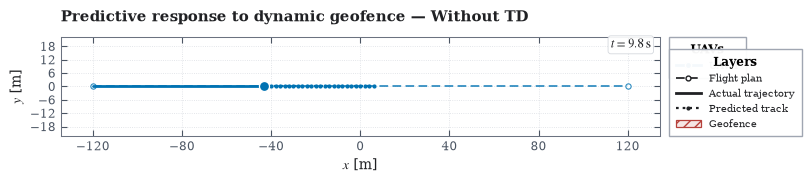

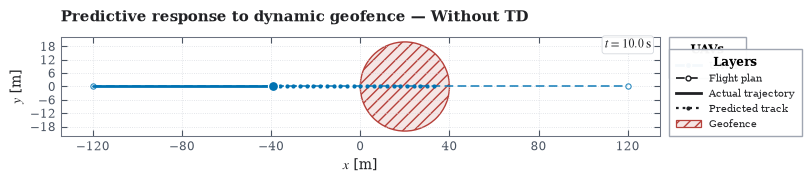

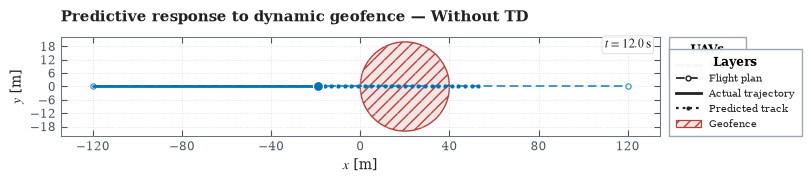

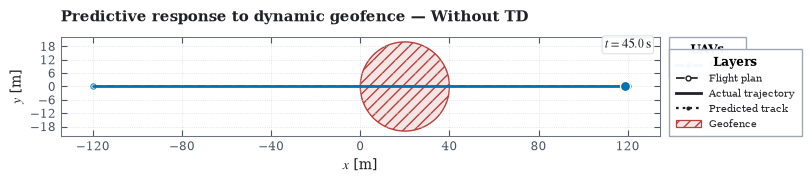

In [ ]:
def visualization_config(case_name):
    return VisualizationConfig(
        uav_names=("UAV 1",),
        view="xy",
        show_real_trajectories=True,
        show_current_positions=True,
        show_tracks=True,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_geofences=True,
        show_wind_zones=False,
        show_obstacles=False,
        frame_step=0.25,
        title=f"Predictive response to dynamic geofence — {case_name}",
        spatial_unit="m",
    )

animation_paths = {}
for case_name, dataset_path in dataset_paths.items():
    file_label = case_name.lower().replace(" ", "_")
    config = visualization_config(case_name)
    for timestamp, stage in (
        (BEFORE_ACTIVATION_TIME, "before_activation"),
        (GEOFENCE_ACTIVATION_TIME, "at_activation"),
        (AFTER_ACTIVATION_TIME, "after_activation"),
        (SIMULATION_END, "final"),
    ):
        figure = plot_dataset(
            dataset_path=dataset_path,
            config=config,
            timestamp=timestamp,
            output_path=FIGURE_DIRECTORY / f"{file_label}_{stage}.png",
        )
        display(figure)
    animation_path = FIGURE_DIRECTORY / f"{file_label}.gif"
    animate_dataset(
        dataset_path=dataset_path,
        config=config,
        output_path=animation_path,
        fps=10.0,
    )
    animation_paths[case_name] = animation_path

print("Figures:", FIGURE_DIRECTORY.resolve())

In [ ]:
for case_name, animation_path in animation_paths.items():
    display(Markdown(f"### {case_name}"))
    display(Image(filename=animation_path))